In [1]:
import pandas as pd
import numpy as np
import sys
from pathlib import Path
import xarray as xr
import os
from datetime import datetime
import matplotlib.pyplot as plt
import geopandas as gpd
import xarray as xr
import matplotlib.pyplot as plt
import cartopy.crs as ccrs
import cartopy.feature as cfeature
import numpy as np

current_path = Path.cwd()

# Search for the utilities directory
for parent in current_path.parents:
    candidate = parent / "utilities"
    if candidate.is_dir():
        sys.path.insert(0, str(parent))
        break
else:
    raise FileNotFoundError("Could not locate 'utilities' directory in parent paths.")

from utilities import init_notebook_environment
from utilities import get_dataset_products,get_prod_files,dataset_defaults,file_parser, get_dataset_dirs, get_dataset_products,run_globcolour_dataset
from utilities import get_nc_prod,product_defaults,netcdf_product_defaults,get_datasets_path,get_dataset_dirs
from utilities import run_stats_pipeline,build_stats_map, run_pp_pipeline, load_dataset
from utilities import build_product_attributes, build_stat_attributes, run_psc_pipeline, find_text, dataset_defaults, parse_dataset_info, hash_grid,build_pp_date_map
from utilities import get_file_dates, get_filepath, get_period_info, get_period_sets, get_period_dates, get_daterange, generate_periods
from utilities import get_clim_period,extract_period_code,get_daylength,run_globcolour_dataset
from utilities import build_anomaly_map, run_anomaly_pipeline, batch_anomaly_match


env = init_notebook_environment(verbose=False)


In [3]:
get_filepath('CHL',data_type='EXTRACT',region_name='NES_EPU_NOESTUARIES')

'/Users/kimberly.hyde/Documents/nadata/DATASETS/OCCCI/V6.0/EXTRACTED_DATA/NES_EPU_NOESTUARIES'

In [3]:
build_stats_map('CHL',period='M',verify_existing=True)

⚠ WARNING: Path not found: /Users/kimberly.hyde/Documents/nadata/DATASETS/OCCCI/V6.0/SOURCE/NWA_4KM_DAILY/CHL
Closest existing parent: /Users/kimberly.hyde/Documents/nadata/DATASETS/OCCCI/V6.0/SOURCE
Available subdirectories in parent: ['GLOBAL_4KM_DAILY_RAN']
⚠ WARNING: Path not found: /Users/kimberly.hyde/Documents/nadata/DATASETS/OCCCI/V6.0/SOURCE/NWA_4KM_DAILY/CHL
Closest existing parent: /Users/kimberly.hyde/Documents/nadata/DATASETS/OCCCI/V6.0/SOURCE
Available subdirectories in parent: ['GLOBAL_4KM_DAILY_RAN']
------------------------------------------------------------
📊 STATS SUMMARY: CHL | M | NWA
📁 Output Dir: /Users/kimberly.hyde/Documents/nadata/DATASETS/OCCCI/V6.0/PRODUCTS/NWA_4KM_MONTHLY/CHL
✅ Up-to-date:  1/346 (0.3%)
⏳ To process:  345 files
------------------------------------------------------------


({'M_199709': {'inputs': ['/Users/kimberly.hyde/Documents/nadata/DATASETS/OCCCI/V6.0/SOURCE/GLOBAL_4KM_DAILY_RAN/CHL/ESACCI-OC-L3S-CHLOR_A-MERGED-1D_DAILY_4km_GEO_PML_OCx-19970906-fv6.0.nc',
    '/Users/kimberly.hyde/Documents/nadata/DATASETS/OCCCI/V6.0/SOURCE/GLOBAL_4KM_DAILY_RAN/CHL/ESACCI-OC-L3S-CHLOR_A-MERGED-1D_DAILY_4km_GEO_PML_OCx-19970909-fv6.0.nc',
    '/Users/kimberly.hyde/Documents/nadata/DATASETS/OCCCI/V6.0/SOURCE/GLOBAL_4KM_DAILY_RAN/CHL/ESACCI-OC-L3S-CHLOR_A-MERGED-1D_DAILY_4km_GEO_PML_OCx-19970910-fv6.0.nc',
    '/Users/kimberly.hyde/Documents/nadata/DATASETS/OCCCI/V6.0/SOURCE/GLOBAL_4KM_DAILY_RAN/CHL/ESACCI-OC-L3S-CHLOR_A-MERGED-1D_DAILY_4km_GEO_PML_OCx-19970915-fv6.0.nc',
    '/Users/kimberly.hyde/Documents/nadata/DATASETS/OCCCI/V6.0/SOURCE/GLOBAL_4KM_DAILY_RAN/CHL/ESACCI-OC-L3S-CHLOR_A-MERGED-1D_DAILY_4km_GEO_PML_OCx-19970916-fv6.0.nc'],
   'output': '/Users/kimberly.hyde/Documents/nadata/DATASETS/OCCCI/V6.0/PRODUCTS/NWA_4KM_MONTHLY/CHL/M_199709-NWA-OCCCI-CHL-STATS.nc

Loading /Users/kimberly.hyde/Documents/nadata/DATASETS/OCCCI/V6.0/PRODUCTS/NWA_4KM_MONTHLY/CHL/M_202501-NWA-OCCCI-CHL-ANOM.nc...


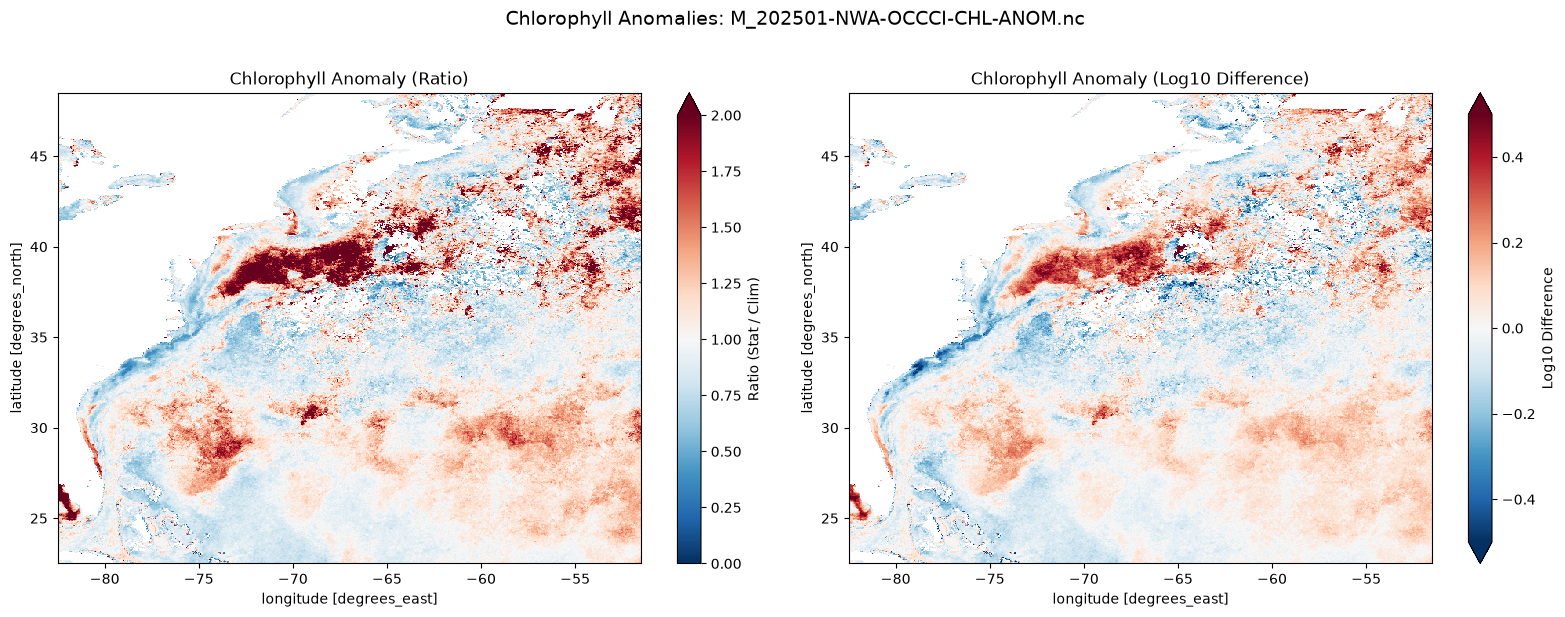

In [3]:
def plot_chl_anomalies(nc_filepath):
    # Load the NetCDF file
    print(f"Loading {nc_filepath}...")
    ds = xr.open_dataset(nc_filepath)
    
    # Create a figure with two subplots side-by-side
    fig, axes = plt.subplots(ncols=2, figsize=(16, 6))
    
    # 1. Plot the Ratio Anomaly
    if 'CHL_anom_ratio' in ds.data_vars:
        # Centered at 1.0 (Normal baseline for ratios)
        ds['CHL_anom_ratio'].plot(
            ax=axes[0], 
            cmap='RdBu_r', 
            vmin=0.0, vmax=2.0, # Adjust these limits based on your data spread
            cbar_kwargs={'label': 'Ratio (Stat / Clim)'}
        )
        axes[0].set_title('Chlorophyll Anomaly (Ratio)')
    else:
        axes[0].set_title('CHL_anom_ratio not found')

    # 2. Plot the Log-Difference Anomaly
    if 'CHL_anom_logdif' in ds.data_vars:
        # Centered at 0.0 (Normal baseline for differences)
        ds['CHL_anom_logdif'].plot(
            ax=axes[1], 
            cmap='RdBu_r', 
            vmin=-0.5, vmax=0.5, # Adjust these limits based on your data spread
            cbar_kwargs={'label': 'Log10 Difference'}
        )
        axes[1].set_title('Chlorophyll Anomaly (Log10 Difference)')
    else:
        axes[1].set_title('CHL_anom_logdif not found')

    # Formatting
    plt.suptitle(f"Chlorophyll Anomalies: {nc_filepath.split('/')[-1]}", fontsize=14, y=1.02)
    plt.tight_layout()
    plt.show()

    # Close dataset to free memory
    ds.close()

# --- Run the script ---
# Replace this with the actual path to your anomaly file
files = get_prod_files('CHL',data_type='ANOM',period='M')
file_path = files[0]
plot_chl_anomalies(file_path)

In [19]:
get_prod_files('CHL',data_type='ANOM',periods='M')

⚠ WARNING: Path not found: /Users/kimberly.hyde/Documents/nadata/DATASETS/OCCCI/V6.0/SOURCE/NWA_4KM_DAILY/CHL
Closest existing parent: /Users/kimberly.hyde/Documents/nadata/DATASETS/OCCCI/V6.0/SOURCE
Available subdirectories in parent: ['GLOBAL_4KM_DAILY_RAN']
⚠ WARNING: Path not found: /Users/kimberly.hyde/Documents/nadata/DATASETS/OCCCI/V6.0/SOURCE/NWA_4KM_DAILY/CHL
Closest existing parent: /Users/kimberly.hyde/Documents/nadata/DATASETS/OCCCI/V6.0/SOURCE
Available subdirectories in parent: ['GLOBAL_4KM_DAILY_RAN']


[]

In [ ]:
run_globcolour_dataset(prods='CHL',map_subset='NWA',verbose=True, debug=True,delete_corrupt=True)

In [ ]:
build_stats_map('PSC_micro',period='M')

In [ ]:
run_pp_pipeline(sst_dataset='CORALSST',map_subset='NWA',verbose=True)

In [ ]:
get_prod_files('CHL',period='D8')

In [ ]:
get_filepath('PPD')

In [ ]:
get_prod_files('PPD')

In [2]:
run_anomaly_pipeline('CHL',periods='M')

------------------------------------------------------------
📊 ANOMALY SUMMARY: CHL | M | NWA
✅ Up-to-date:  0/12
⏳ To process:  12 files
------------------------------------------------------------

🏁 ANOMALY PIPELINE FINISHED SUMMARY
📥 Input files found:       0
🗺️  Climatology files found: 0
⏭  Existing files skipped:  0
🔄 Existing files replaced: 0
🆕 New files created:       12
🗑️ Corrupt outputs deleted: 0
❌ Errors/Not created:      0


In [2]:
run_stats_pipeline('CHL',periods=['D3','D7'])

⚠ WARNING: Path not found: /Users/kimberly.hyde/Documents/nadata/DATASETS/OCCCI/V6.0/SOURCE/NWA_4KM_DAILY/CHL
Closest existing parent: /Users/kimberly.hyde/Documents/nadata/DATASETS/OCCCI/V6.0/SOURCE
Available subdirectories in parent: ['GLOBAL_4KM_DAILY_RAN']
⚠ WARNING: Path not found: /Users/kimberly.hyde/Documents/nadata/DATASETS/OCCCI/V6.0/SOURCE/NWA_4KM_DAILY/CHL
Closest existing parent: /Users/kimberly.hyde/Documents/nadata/DATASETS/OCCCI/V6.0/SOURCE
Available subdirectories in parent: ['GLOBAL_4KM_DAILY_RAN']
------------------------------------------------------------
📊 STATS SUMMARY: CHL | D3 | NWA
📁 Output Dir: /Users/kimberly.hyde/Documents/nadata/DATASETS/OCCCI/V6.0/PRODUCTS/NWA_4KM_DAY3/CHL
✅ Up-to-date:  0/10525 (0.0%)
⏳ To process:  10525 files
------------------------------------------------------------
  Saved: D3_19970906_19970908-NWA-OCCCI-CHL-STATS.nc
  Saved: D3_19970907_19970909-NWA-OCCCI-CHL-STATS.nc
  Saved: D3_19970908_19970910-NWA-OCCCI-CHL-STATS.nc
  Saved: D

In [ ]:
get_prod_files('PSC_Micro',period='W',data_type='ANOM')


In [ ]:
file = '/Volumes/EDAB_Datasets/GLORYS/V12/SOURCE/NES_9KM_DAILY/GLOBAL_MULTIYEAR_PHY_001_030/BOTTOMT/GLORYS_REANALYSIS-DAILY-BOTTOMT-20260825.nc'
xr.open_dataset(file)

        # substitution key for commonly queried variables in cmems and their internal moniker for naming conventions in registry and storage
        "sea_water_potential_temperature_at_sea_floor": "bottomT",
        "sea_water_potential_temperature": "temperature",
        "sea_water_salinity": "salinity",
        "ocean_mixed_layer_thickness_defined_by_sigma_theta": "mixedLayerDepth",
    }

\GLORYS\V12\SOURCE\NES_9KM_DAILY\GLOBAL_MULTIYEAR_PHY_001_030\BOTTOMT\GLORYS_REANALYSIS-DAILY-BOTTOMT-19930101.nc"

In [ ]:
        # substitution key for commonly queried variables in cmems and their internal moniker for naming conventions in registry and storage
        "sea_water_potential_temperature_at_sea_floor": "bottomT",
        "sea_water_potential_temperature": "temperature",
        "sea_water_salinity": "salinity",
        "ocean_mixed_layer_thickness_defined_by_sigma_theta": "mixedLayerDepth",
    }

\GLORYS\V12\SOURCE\NES_9KM_DAILY\GLOBAL_MULTIYEAR_PHY_001_030\BOTTOMT\GLORYS_REANALYSIS-DAILY-BOTTOMT-19930101.nc"

In [ ]:
env

In [ ]:
files = get_prod_files('PSC',map_subset='NWA')
xr.open_dataset(files[0])


In [ ]:
files = get_prod_files(prod='CHL',period='D8',map_subset='NWA',verbose=True)
clim = get_prod_files(prod='CHL',period='DOY',map_subset='NWA',verbose=True)
batch_anomaly_match(files,clim)

In [ ]:
file_parser('/Users/kimberly.hyde/Documents/nadata/DATASETS/OCCCI/V6.0/PRODUCTS/NES_4KM_CLIMATOLOGY/CHL/MONTH_11_1997_2020-OCCCI-CHL-NES-CLIM.nc')

In [ ]:
file_parser('/Users/kimberly.hyde/Documents/nadata/DATASETS/OCCCI/V6.0/PRODUCTS/NES_4KM_MONTHLY/CHL/M_199711-OCCCI-CHL-NES-ANOM.nc')

In [ ]:
prod='CHL'
stat_name = 'anomaly'

build_stat_attributes(prod, "anomaly")

In [ ]:
xr.open_dataset('/Users/kimberly.hyde/Documents/nadata/DATASETS/OCCCI/V6.0/PRODUCTS/NES_4KM_MONTHLY/CHL/M_199711-OCCCI-CHL-NES-ANOM.nc')

In [ ]:
dataset_info_map = dataset_defaults()
_, default_grid, default_product, _ = dataset_info_map['OCCCI']

In [ ]:
get_prod_files('CHL',period='M',map_subset='NES',data_type='ANOM')

In [ ]:
run_anomaly_pipeline('CHL', periods='M',map_subset='NES',verbose=True)

In [ ]:
stat_files = get_prod_files('CHL',period='M',map_subset='NES')
clim_files = get_prod_files('CHL',period='MONTH',map_subset='NES')
amap = batch_anomaly_match(stat_files,clim_files)
# 2. Loop through the successful matches to build your maps
for input_file, matched_clim in amap.items():
    print(f"Processing: {input_file} against {matched_clim}")



In [ ]:
ds = xr.open_mfdataset(stat_files)
print(list(ds.data_vars))

In [ ]:
build_anomaly_map('CHL',period='M',map_subset='NES',verbose=True)

In [ ]:
f = get_prod_files('SST',period='M',map_subset='NWA',verbose=False)
file_parser(f[0])

In [ ]:
files = get_prod_files('CHL',period='DOY',map_subset='NWA',verbose=False,data_type='STATS')
search_text = "STATS"
replace_text = "CLIM"

for file_path in files:
    path_obj = Path(file_path)
    
    # Check if the search string is in the actual file name (ignoring folders)
    if search_text in path_obj.name:
        # Replace the text in the file name
        new_name = path_obj.name.replace(search_text, replace_text)
        
        # Create the new full path
        new_path = path_obj.with_name(new_name)
        
        # Rename the file on the filesystem
        path_obj.rename(new_path)
        print(f"Renamed: {path_obj.name} -> {new_name}")

In [ ]:
get_filepath('CHL',period='M',verbose=False,map_subset='NES') 

In [ ]:
run_pp_pipeline(sst_dataset='CORALSST',map_subset='NWA',verbose=True)

In [ ]:
run_globcolour_dataset(subset_map="NWA", dry_run=False, overwrite=True, verbose=True, debug=False)